# 04 · Tree-based models

Tree ensembles from the task list, all on the log target, on the two best feature sets from notebook 02:
- `estate+fg`: EState + functional groups (65 columns, best MAPE)
- `desc+ecfp+estate+fg`: + descriptors + ECFP (437 columns, best pairwise accuracy)

Models: random forest, ExtraTrees, XGBoost, LightGBM, CatBoost. Three ways to set hyperparameters:
1. **fixed:** small, regularised settings (shallow trees, subsampling)
2. **old tuning:** the old protocol (Optuna, 100 trials, RMSE on one 70/30 split), here on log(y)
3. **inner-CV tuning:** Optuna TPE, 30 trials, 5-fold CV inside each training fold, minimising mean
   absolute log error. Test folds are never seen during tuning (nested CV).

In [1]:
import os
import sys
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from xgboost import XGBRegressor

from cofreg import plots
from cofreg.cv import load_oof, repeated_folds, run_many
from cofreg.data import RESULTS_DIR, load_data, load_features
from cofreg.models import InnerCVTuned, OldProtocolTuned, TargetTransformed

plots.style()
EXPERIMENT = "04_tree_models"
y = load_data().capacity_max.to_numpy()
repeats = repeated_folds(y)
FEATURES = {
    "estate+fg": load_features("estate", "functional_groups"),
    "desc+ecfp+estate+fg": load_features("descriptor", "ecfp", "estate", "functional_groups"),
}
log = lambda model: TargetTransformed(model, "log")

In [2]:
FIXED = {
    "rf": lambda: RandomForestRegressor(500, min_samples_leaf=2, max_features=0.3, random_state=0, n_jobs=1),
    "extratrees": lambda: ExtraTreesRegressor(500, min_samples_leaf=2, max_features=0.3, random_state=0, n_jobs=1),
    "xgboost": lambda: XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.5, min_child_weight=2, n_jobs=1, random_state=0),
    "lightgbm": lambda: LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=5, subsample=0.8, subsample_freq=1, colsample_bytree=0.5, verbose=-1, n_jobs=1, random_state=0),
    "catboost": lambda: CatBoostRegressor(iterations=500, depth=4, learning_rate=0.03, verbose=0, thread_count=1, random_seed=0),
}
configs = [(f"{m} | {f}", log(make()), X, f) for f, X in FEATURES.items() for m, make in FIXED.items()]
configs += [(f"{m}_oldtuning | {f}", log(OldProtocolTuned(m)), X, f) for f, X in FEATURES.items() for m in ["random_forest", "xgboost"]]
summary_fixed = run_many(configs, y, repeats, EXPERIMENT)

rf | estate+fg                                MAPE 1.397±0.070  PA 0.677±0.008  RMSE 187.0±3.1  MALE 0.688  (4.1s)


extratrees | estate+fg                        MAPE 1.570±0.047  PA 0.663±0.007  RMSE 193.8±1.8  MALE 0.725  (1.7s)


xgboost | estate+fg                           MAPE 1.536±0.142  PA 0.666±0.016  RMSE 194.5±4.9  MALE 0.706  (2.1s)


lightgbm | estate+fg                          MAPE 1.618±0.096  PA 0.658±0.013  RMSE 213.1±5.7  MALE 0.761  (0.2s)


catboost | estate+fg                          MAPE 1.459±0.156  PA 0.665±0.012  RMSE 189.7±5.8  MALE 0.702  (1.3s)


...

catboost | desc+ecfp+estate+fg                MAPE 1.497±0.121  PA 0.677±0.012  RMSE 191.3±3.9  MALE 0.689  (3.5s)


random_forest_oldtuning | estate+fg           MAPE 1.586±0.172  PA 0.661±0.014  RMSE 187.0±4.6  MALE 0.728  (26.4s)


xgboost_oldtuning | estate+fg                 MAPE 1.732±0.120  PA 0.663±0.018  RMSE 194.0±6.2  MALE 0.713  (5.3s)


random_forest_oldtuning | desc+ecfp+estate+fg MAPE 1.698±0.126  PA 0.680±0.004  RMSE 185.0±3.1  MALE 0.711  (51.6s)


xgboost_oldtuning | desc+ecfp+estate+fg       MAPE 1.878±0.114  PA 0.674±0.019  RMSE 193.3±5.3  MALE 0.731  (10.5s)


## Inner-CV tuning

Search spaces (prefix `regressor__` because the model sits inside the log-target wrapper). This is the
slowest cell (a few minutes on 16 cores).

In [3]:
RF_SPACE = {
    "regressor__min_samples_leaf": ("int", 1, 8),
    "regressor__max_features": ("float", 0.1, 1.0),
    "regressor__max_depth": ("cat", [None, 4, 8, 16]),
}
CAT_SPACE = {
    "regressor__depth": ("int", 2, 8),
    "regressor__learning_rate": ("logfloat", 0.01, 0.2),
    "regressor__l2_leaf_reg": ("logfloat", 1.0, 30.0),
    "regressor__iterations": ("cat", [200, 500, 1000]),
}
tuned = [
    (f"rf_innercv | {f}", InnerCVTuned(log(FIXED["rf"]()), RF_SPACE, n_trials=30), X, f)
    for f, X in FEATURES.items()
] + [
    (f"catboost_innercv | {f}", InnerCVTuned(log(FIXED["catboost"]()), CAT_SPACE, n_trials=30), X, f)
    for f, X in FEATURES.items()
]
summary_tuned = run_many(tuned, y, repeats, EXPERIMENT)
summary = pd.concat([summary_fixed, summary_tuned], ignore_index=True)
summary.to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary.csv"), index=False)

rf_innercv | estate+fg                        MAPE 1.402±0.069  PA 0.679±0.011  RMSE 180.5±3.6  MALE 0.679  (349.9s)


rf_innercv | desc+ecfp+estate+fg              MAPE 1.576±0.092  PA 0.684±0.007  RMSE 186.3±3.2  MALE 0.694  (515.3s)


catboost_innercv | estate+fg                  MAPE 1.572±0.151  PA 0.667±0.018  RMSE 189.5±9.2  MALE 0.700  (372.7s)


catboost_innercv | desc+ecfp+estate+fg        MAPE 1.558±0.131  PA 0.673±0.007  RMSE 194.0±3.8  MALE 0.697  (1710.0s)


In [4]:
summary = summary.sort_values(["features", "model"]).reset_index(drop=True)
summary[["model", "mape_mean", "pa_mean", "pa_std", "rmse_mean", "male_mean", "mape_ge20_mean", "r2_mean", "seconds"]].round(3)

,model,mape_mean,pa_mean,pa_std,rmse_mean,male_mean,mape_ge20_mean,r2_mean,seconds
0,catboost | desc+ecfp+estate+fg,1.497,0.677,0.012,191.340,0.689,0.634,0.044,3.5
1,catboost_innercv | desc+ecfp+estate+fg,1.558,0.673,0.007,193.994,0.697,0.671,0.017,1710.0
2,extratrees | desc+ecfp+estate+fg,1.829,0.667,0.007,193.456,0.724,0.682,0.023,2.9
3,lightgbm | desc+ecfp+estate+fg,1.611,0.673,0.010,200.368,0.730,0.694,-0.049,0.3
4,random_forest_oldtuning | desc+ecfp+estate+fg,1.698,0.680,0.004,185.046,0.711,0.630,0.106,51.6
5,rf | desc+ecfp+estate+fg,1.580,0.685,0.008,187.248,0.692,0.606,0.084,3.5
6,rf_innercv | desc+ecfp+estate+fg,1.576,0.684,0.007,186.290,0.694,0.600,0.094,515.3
7,xgboost | desc+ecfp+estate+fg,1.505,0.682,0.013,192.020,0.692,0.631,0.037,0.4
8,xgboost_oldtuning | desc+ecfp+estate+fg,1.878,0.674,0.019,193.302,0.731,0.618,0.024,10.5
9,catboost | estate+fg,1.459,0.665,0.012,189.697,0.702,0.690,0.060,1.3


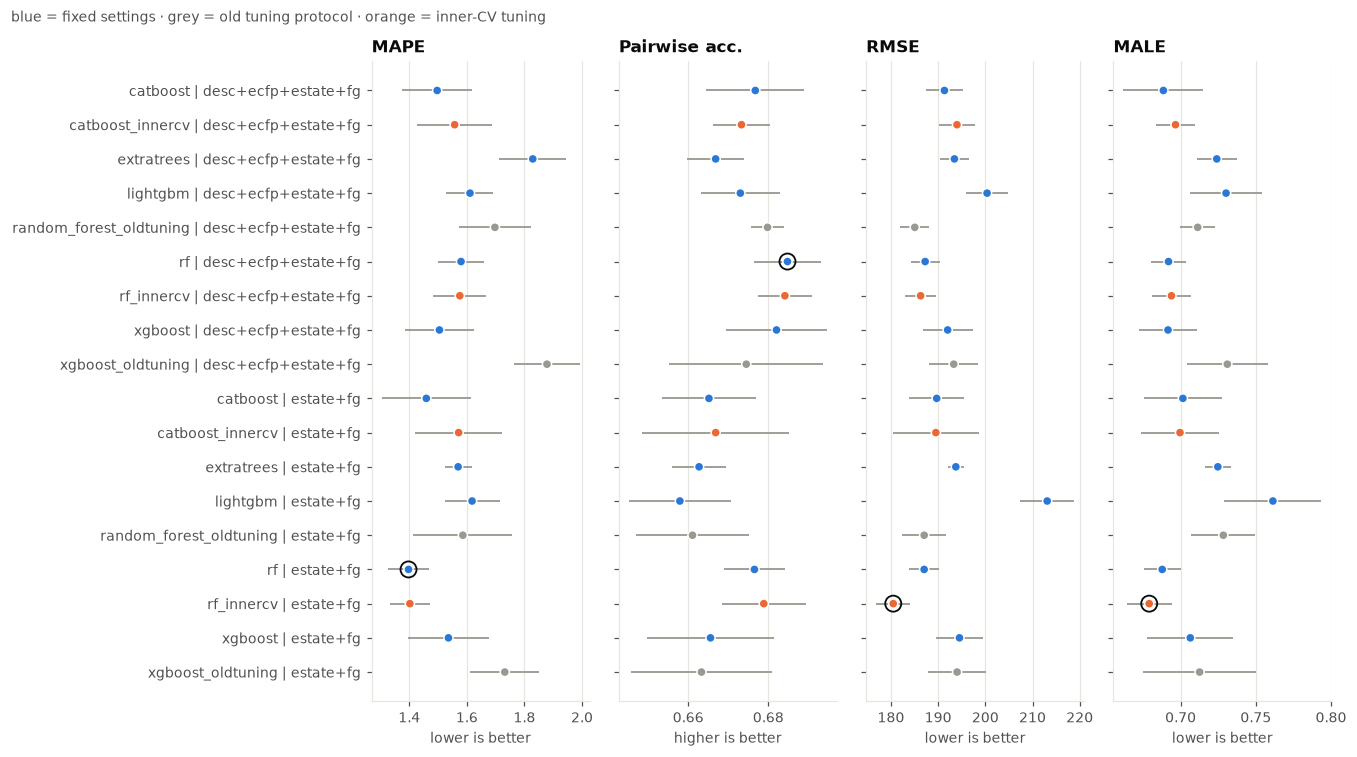

In [5]:
hl = {m: plots.ORANGE if "innercv" in m else plots.GRAY if "oldtuning" in m else plots.BLUE for m in summary["model"]}
fig = plots.metric_dots(summary, highlight=hl)
fig.suptitle("blue = fixed settings · grey = old tuning protocol · orange = inner-CV tuning", x=0.01, ha="left", fontsize=9, color=plots.INK_2)
fig.tight_layout()

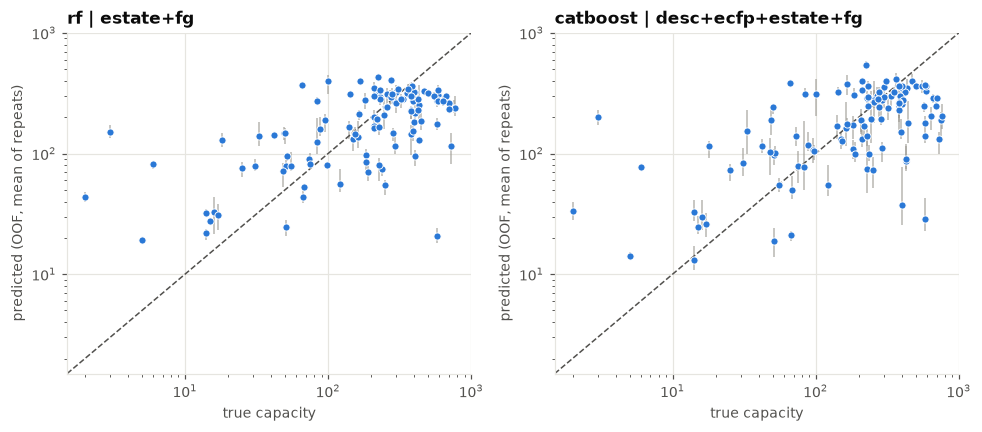

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, ["rf | estate+fg", "catboost | desc+ecfp+estate+fg"]):
    plots.pred_vs_true(y, load_oof(EXPERIMENT, name)[1], name, ax=ax)
fig.tight_layout()

## Takeaways

- All tree ensembles land in a narrow band (PA 0.658–0.685, MALE 0.68–0.76). **Random forest is the
  most reliable:** best or close to best on every metric, on both feature sets, with fixed settings.
- On the larger feature set (descriptors + ECFP + EState + fg), RF, XGBoost and CatBoost all reach
  PA ≈ 0.68; ExtraTrees and LightGBM are a bit worse.
- **Tuning helps little.** The old protocol (single 70/30 split, RMSE) is no better than fixed settings,
  often worse. Nested inner-CV tuning gives RF a small gain on EState + fg (RMSE 187.0 → 180.5, MALE
  0.688 → 0.679, same PA) at ~100× the compute; for CatBoost it gives nothing.
- With ~100 training samples per fold, regularised defaults are a good choice; tuning is mostly fitting noise.